# NicheEnergy tutorial: human MERFISH MTG

In [1]:
from pathlib import Path
import os
import json
import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import rankdata
from scipy.optimize import linear_sum_assignment
import torch
from scvi import settings
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from umap import UMAP
from nicheenergy import NicheEnergy

# plt.rcParams.update({"figure.dpi": 180, "savefig.dpi": 300, "font.size": 12,
#                      "axes.titlesize": 15, "axes.labelsize": 13,
#                      "pdf.fonttype": 42, "svg.fonttype": "none"})

/data/data2/zhenglab/.local/share/mamba/envs/simvi/lib/python3.10/site-packages/pytorch_lightning/utilities/seed.py:48: LightningDeprecationWarning: `pytorch_lightning.utilities.seed.seed_everything` has been deprecated in v1.8.0 and will be removed in v1.10.0. Please use `lightning_lite.utilities.seed.seed_everything` instead.
  rank_zero_deprecation(
Global seed set to 0
/data/data2/zhenglab/.local/share/mamba/envs/simvi/lib/python3.10/site-packages/pytorch_lightning/loggers/base.py:24: LightningDeprecationWarning: The `pytorch_lightning.loggers.base.rank_zero_experiment` is deprecated in v1.7 and will be removed in v1.9. Please use `pytorch_lightning.loggers.logger.rank_zero_experiment` instead.
  rank_zero_deprecation(


In [2]:
DATA_DIR = Path(os.environ.get("NICHEENERGY_MTG_DATA", str(Path.home() / "NicheEnergy_data" / "prepared" / "MTG")))
OUTPUT_DIR = Path(os.environ.get("NICHEENERGY_MTG_OUTPUT", str(Path.home() / "NicheEnergy_results" / "MTG_tutorial_seed0")))
SEED = 0
MAX_EPOCHS = 100
N_NICHES = 5

settings.seed = SEED
torch.set_num_threads(2)
torch.backends.cudnn.benchmark = False
device = torch.device("cuda")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

/data/data2/zhenglab/.local/share/mamba/envs/simvi/lib/python3.10/site-packages/pytorch_lightning/utilities/seed.py:48: LightningDeprecationWarning: `pytorch_lightning.utilities.seed.seed_everything` has been deprecated in v1.8.0 and will be removed in v1.10.0. Please use `lightning_lite.utilities.seed.seed_everything` instead.
  rank_zero_deprecation(
Global seed set to 0


In [3]:
adata = ad.read_h5ad(DATA_DIR / "input.h5ad")
reference = pd.read_csv(DATA_DIR / "obs.csv.gz", dtype={"obs_name": str}).set_index("obs_name")
assert adata.obs_names.is_unique and adata.var_names.is_unique
assert reference.index.is_unique
reference = reference.loc[adata.obs_names].copy()
obs_names = adata.obs_names.to_numpy(dtype=str)
counts = adata.X.data if sp.issparse(adata.X) else np.asarray(adata.X)
assert np.isfinite(counts).all() and (counts >= 0).all()
assert np.allclose(counts, np.rint(counts))
assert np.isfinite(adata.obsm["spatial"]).all()
adata.obs["batch"] = adata.obs["batch"].astype("category")
sections = list(adata.obs["batch"].cat.categories)
section_labels = {"rep1": "Replicate 1", "rep2": "Replicate 2", "rep3": "Replicate 3"}
batch = adata.obs["batch"].astype(str).to_numpy()
coordinates = np.asarray(adata.obsm["spatial"])
cell_type = reference["cell_type"].astype(str).to_numpy()
adata.obs["cell_type"] = pd.Categorical(cell_type)
layer_names = [f"L{i}" for i in range(1, 7)]
reference_layer = reference["niche"].str.replace(r"^N", "L", regex=True).to_numpy()
assert set(reference_layer) == set(layer_names)
adata.obs["reference_layer"] = pd.Categorical(reference_layer, categories=layer_names)
print(adata)

AnnData object with n_obs × n_vars = 11059 × 4000
    obs: 'batch', 'cell_type', 'reference_layer'
    obsm: 'spatial'


In [4]:
NicheEnergy.setup_anndata(adata, batch_key="batch")
graph = NicheEnergy.extract_edge_index_and_distance(adata, batch_key="batch")
model = NicheEnergy(adata)
train_loss, validation_loss = model.train(graph, max_epochs=MAX_EPOCHS, use_gpu=True, device=device)
assert np.isfinite(train_loss).all() and np.isfinite(validation_loss).all()


CUDA backend failed to initialize: Unable to use CUDA because of the following issues with CUDA components:
Unable to load cuDNN. Is it installed?
Traceback (most recent call last):
  File "/data/data2/zhenglab/.local/share/mamba/envs/simvi/lib/python3.10/site-packages/jax/_src/xla_bridge.py", line 339, in _version_check
    version = get_version()
RuntimeError: cuDNN not found.

--------------------------------------------------
Outdated cuSPARSE installation found.
Version JAX was built against: 12200
Minimum supported: 12100
Installed version: 12002
The local installation version must be no lower than 12100..(Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


Using z-only adversarial batch loss: adv_weight=10.0, adv_lr=0.001, adversarial_step=1, adv_on=sample


Epoch 100/100: 100%|██████████| 100/100 [01:01<00:00,  1.62it/s, train_loss=1.42e+3, val_loss=1429.6731]


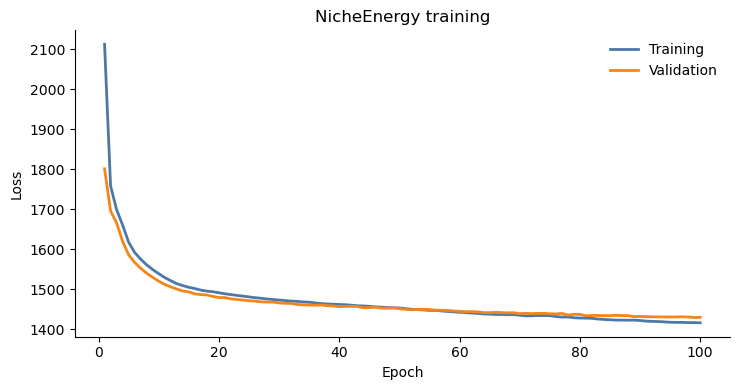

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(np.arange(1, len(train_loss) + 1), train_loss, label="Training", color="#4C78A8", lw=2)
ax.plot(np.arange(1, len(validation_loss) + 1), validation_loss, label="Validation", color="#F58518", lw=2)
ax.set(xlabel="Epoch", ylabel="Loss", title="NicheEnergy training")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_loss.png", bbox_inches="tight")
plt.show()

In [6]:
model.module.eval()
inference_graph = tuple(tensor.to(device) for tensor in graph)
with torch.no_grad():
    z = model.get_latent_representation(inference_graph, representation_kind="intrinsic", give_mean=True)
    s = model.get_latent_representation(inference_graph, representation_kind="interaction", give_mean=True)
assert z.shape == s.shape == (adata.n_obs, 20)
assert np.isfinite(z).all() and np.isfinite(s).all()
adata.obsm["nicheenergy_z"] = z
adata.obsm["nicheenergy_s"] = s

umap_options = dict(n_neighbors=15, min_dist=0.25, metric="euclidean", random_state=SEED, n_jobs=1)
z_umap = UMAP(**umap_options).fit_transform(z)
s_umap = UMAP(**umap_options).fit_transform(s)
adata.obsm["X_umap_z"] = z_umap
adata.obsm["X_umap_s"] = s_umap

In [7]:
cell_colors = {"EXC": "#4C78A8", "INC": "#F58518", "lASC": "#54A24B", "lMGC": "#E45756",
               "lOGC": "#7654A2", "lOPC": "#8C564B", "oENDO": "#E377C2", "oMURAL": "#7F7F7F"}
batch_colors = {"rep1": "#1f77b4", "rep2": "#ff7f0e", "rep3": "#2ca02c"}
layer_colors = dict(zip(layer_names,
                       ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]))

def category_plot(ax, xy, labels, colors, title, spatial=False, legend=True):
    order = np.random.default_rng(SEED).permutation(len(xy))
    values = np.asarray(labels).astype(str)
    point_colors = [colors[label] for label in values[order]]
    ax.scatter(xy[order, 0], xy[order, 1], c=point_colors, s=4,
               linewidths=0, alpha=0.9, rasterized=True)
    ax.set_title(title, pad=12)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#bdbdbd")
    if spatial:
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.set(xlabel="Spatial x", ylabel="Spatial y")
    else:
        ax.set(xlabel="UMAP1", ylabel="UMAP2")
    if legend:
        handles = [Line2D([], [], marker="s", linestyle="", markersize=8,
                          color=color, label=section_labels.get(label, label))
                   for label, color in colors.items() if label in values]
        ax.legend(handles=handles, frameon=False, loc="upper left",
                  bbox_to_anchor=(1.01, 1), borderaxespad=0, fontsize=11)

In [8]:
fit_mask = ~np.isin(cell_type, ["oENDO", "oMURAL"])
kmeans = KMeans(n_clusters=N_NICHES, random_state=SEED, n_init=50,
                max_iter=300, tol=1e-4, algorithm="lloyd")
kmeans.fit(s[fit_mask])
inferred_niche = np.array([f"C{i + 1}" for i in kmeans.predict(s)])
adata.obs["inferred_niche"] = pd.Categorical(inferred_niche)
adata.obs["niche_fit_eligible"] = fit_mask
# Match colors to reference layers for display only.
niche_names = [f"C{i}" for i in range(1, N_NICHES + 1)]
contingency = pd.crosstab(inferred_niche[fit_mask], reference_layer[fit_mask]).reindex(
    index=niche_names, columns=layer_names, fill_value=0)
cluster_indices, layer_indices = linear_sum_assignment(-contingency.to_numpy())
niche_colors = {niche_names[i]: layer_colors[layer_names[j]]
                for i, j in zip(cluster_indices, layer_indices)}


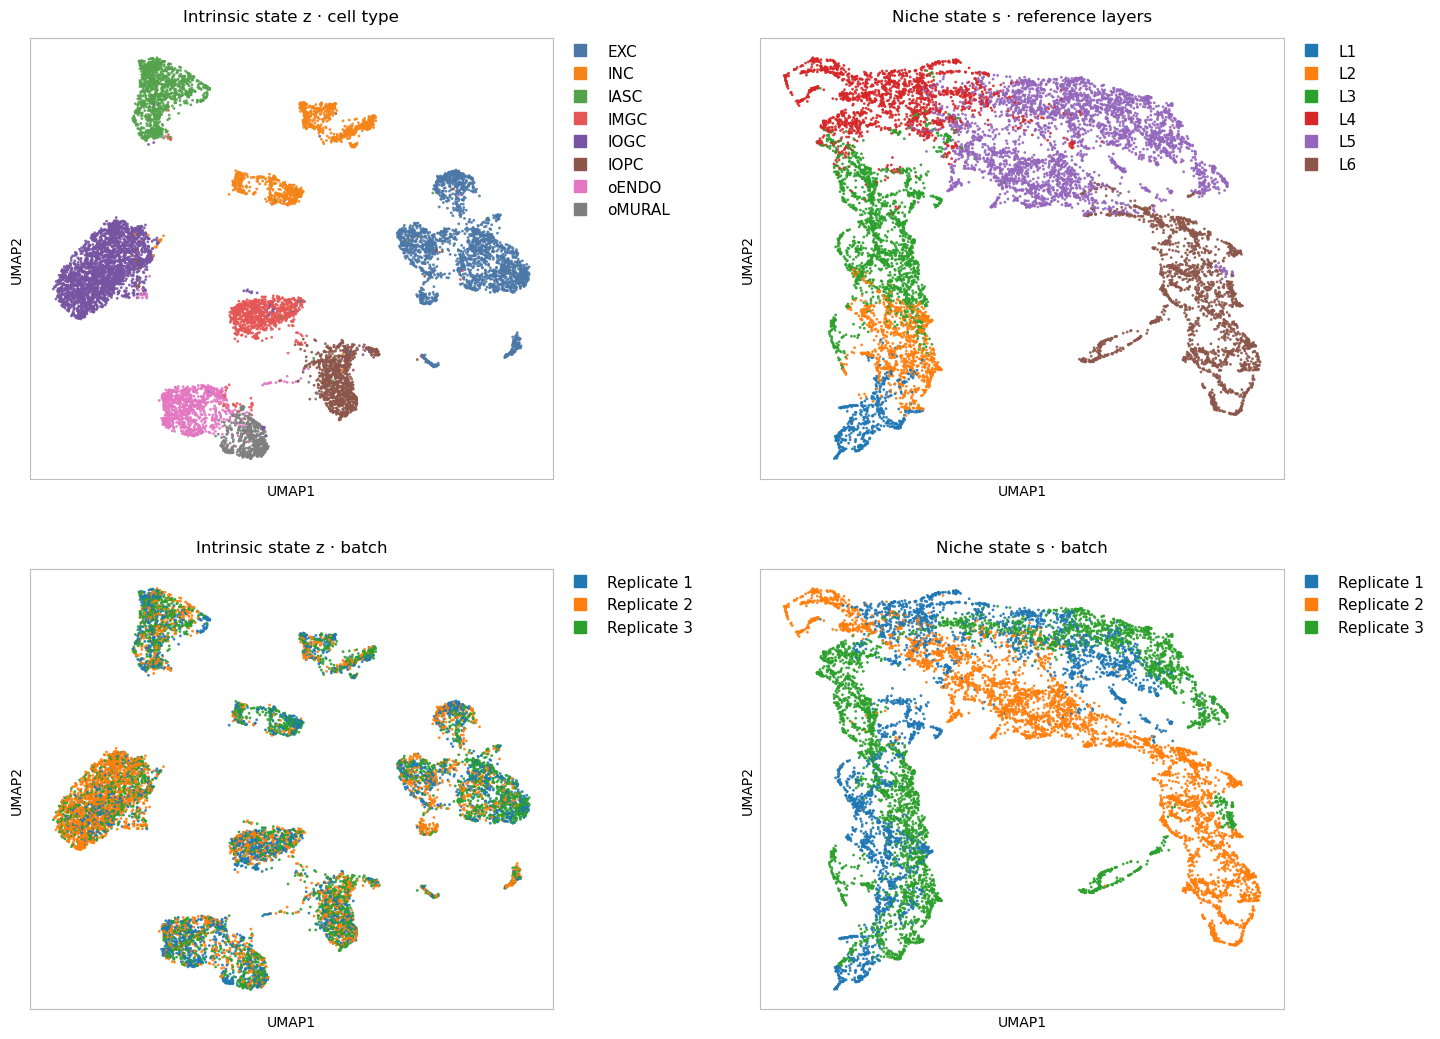

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14.5, 10.5))
category_plot(axes[0, 0], z_umap, cell_type, cell_colors, "Intrinsic state z · cell type")
category_plot(axes[0, 1], s_umap, reference_layer, layer_colors, "Niche state s · reference layers")
category_plot(axes[1, 0], z_umap, batch, batch_colors, "Intrinsic state z · batch")
category_plot(axes[1, 1], s_umap, batch, batch_colors, "Niche state s · batch")
fig.tight_layout(w_pad=3, h_pad=3)
fig.savefig(OUTPUT_DIR / "umap_z_s.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "umap_z_s.pdf", bbox_inches="tight")
plt.show()

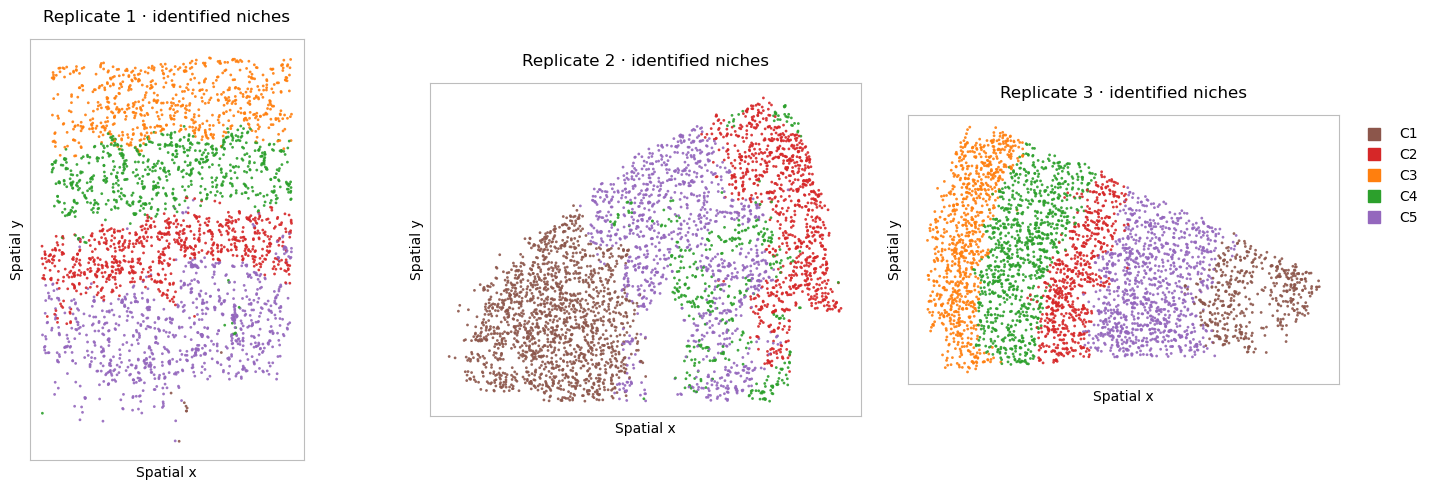

In [10]:
fig, axes = plt.subplots(1, len(sections), figsize=(15, 5), squeeze=False)
for column, section in enumerate(sections):
    selected = batch == section
    category_plot(axes[0, column], coordinates[selected], inferred_niche[selected], niche_colors,
                  f"{section_labels[section]} · identified niches", spatial=True, legend=False)
handles = [Line2D([], [], marker="s", linestyle="", color=color, markersize=8, label=label)
           for label, color in niche_colors.items()]
axes[0, -1].legend(handles=handles, frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout(w_pad=2)
fig.savefig(OUTPUT_DIR / "niche_identification.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "niche_identification.pdf", bbox_inches="tight")
plt.show()


In [11]:
focal_parts, neighbor_parts, distance_parts = [], [], []
for section in sections:
    indices = np.flatnonzero(batch == section)
    neighbors = NearestNeighbors(n_neighbors=40, n_jobs=2).fit(coordinates[indices])
    distances, local_neighbors = neighbors.kneighbors(None)
    focal_parts.append(np.repeat(indices, 40))
    neighbor_parts.append(indices[local_neighbors.ravel()])
    distance_parts.append(distances.ravel().astype(np.float32))
focal = np.concatenate(focal_parts)
neighbor = np.concatenate(neighbor_parts)
distance = np.concatenate(distance_parts)
middle = (len(distance) - 1) // 2
distance_scale = max(float(np.partition(distance, middle)[middle]), 1e-8)
z_norm = np.linalg.norm(z, axis=1).astype(np.float32)
numerator = np.zeros(adata.n_obs, dtype=np.float64)
denominator = np.zeros(adata.n_obs, dtype=np.float64)
for start in range(0, len(focal), 250000):
    stop = min(start + 250000, len(focal))
    i, j = focal[start:stop], neighbor[start:stop]
    difference = s[i] - s[j]
    squared_difference = np.einsum("ij,ij->i", difference, difference, optimize=True)
    cosine = np.einsum("ij,ij->i", z[i], z[j], optimize=True) / np.maximum(z_norm[i] * z_norm[j], 1e-8)
    intrinsic_weight = np.clip(0.5 * (1 + cosine), 0, 1).astype(np.float32)
    distance_weight = (0.7 + 0.3 / (1 + distance[start:stop] / distance_scale)).astype(np.float32)
    weight = intrinsic_weight * distance_weight
    np.add.at(numerator, i, weight * squared_difference)
    np.add.at(denominator, i, weight)
assert (denominator > 0).all()
energy = (numerator / denominator).astype(np.float32)
energy_percentile = np.empty(adata.n_obs, dtype=np.float32)
for section in sections:
    selected = batch == section
    energy_percentile[selected] = rankdata(energy[selected], method="average") / (selected.sum() + 1)
adata.obs["niche_energy"] = energy
adata.obs["niche_energy_percentile"] = energy_percentile

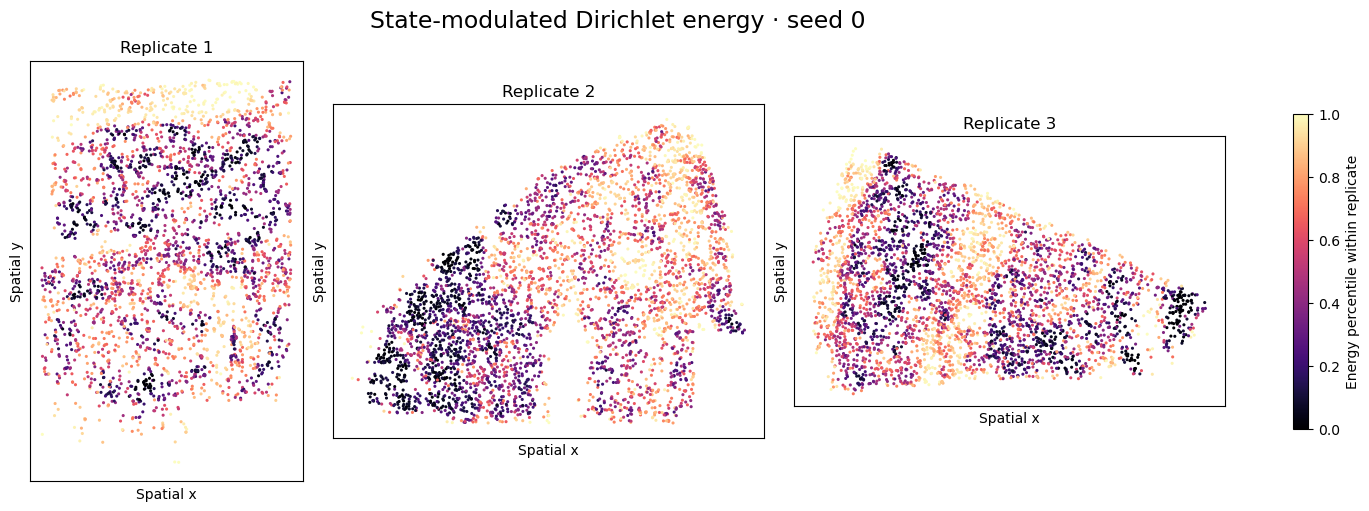

In [12]:
fig, axes = plt.subplots(1, len(sections), figsize=(15, 5), squeeze=False, constrained_layout=True)
for ax, section in zip(axes[0], sections):
    indices = np.flatnonzero(batch == section)
    indices = np.random.default_rng(SEED).permutation(indices)
    points = ax.scatter(coordinates[indices, 0], coordinates[indices, 1], c=energy_percentile[indices],
                        cmap="magma", vmin=0, vmax=1, s=5, linewidths=0, rasterized=True)
    ax.set(title=section_labels[section], xlabel="Spatial x", ylabel="Spatial y", aspect="equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.invert_yaxis()
fig.suptitle(f"State-modulated Dirichlet energy · seed {SEED}", fontsize=17)
fig.colorbar(points, ax=list(axes[0]), shrink=0.75, label="Energy percentile within replicate")
fig.savefig(OUTPUT_DIR / "niche_energy.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "niche_energy.pdf", bbox_inches="tight")
plt.show()

In [13]:
np.savez_compressed(OUTPUT_DIR / "embeddings.npz", z=z, s=s, obs_names=obs_names,
                    z_umap=z_umap, s_umap=s_umap)
np.savez_compressed(OUTPUT_DIR / "losses.npz", train=train_loss, validation=validation_loss)
adata.write_h5ad(OUTPUT_DIR / "MTG_nicheenergy.h5ad")
adata.obs.to_csv(OUTPUT_DIR / "cell_results.csv.gz")
model_config = model.init_params_["non_kwargs"].copy()
torch.save({"state_dict": model.module.state_dict(), "model_config": model_config,
            "seed": SEED,
            "var_names": adata.var_names.astype(str).tolist()}, OUTPUT_DIR / "model.pt")
run = {"seed": SEED, "model": model_config, "epochs": MAX_EPOCHS,
       "umap": umap_options, "niche_clustering": kmeans.get_params(),
       "niche_fit_cells": int(fit_mask.sum()), "energy_model_seed": SEED,
       "energy_graph_neighbors": 40, "energy_distance_scale": distance_scale}
(OUTPUT_DIR / "run.json").write_text(json.dumps(run, indent=2) + "\n")
print("Saved:", sorted(path.name for path in OUTPUT_DIR.iterdir()))

Saved: ['MTG_nicheenergy.h5ad', 'cell_results.csv.gz', 'embeddings.npz', 'losses.npz', 'model.pt', 'niche_energy.pdf', 'niche_energy.png', 'niche_identification.pdf', 'niche_identification.png', 'run.json', 'training_loss.png', 'umap_z_s.pdf', 'umap_z_s.png']
